# Tema 18 · PyTorch: tensores, autograd y el bucle de entrenamiento

La herramienta profesional para todo lo que viene después.

Este cuaderno es el tema 18 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/18-pytorch-tensores-autograd-y-el-bucle-de-entrenamiento/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

# Teoría

## La pregunta

En el tema 17 construiste tu propio motor de gradientes, la clase `Valor`, y entrenaste con él una red pequeña que separaba dos lunas: unos 30 parámetros y 30 puntos. Ahora imagina una tarea de verdad: mirar una foto en blanco y negro de 28 × 28 píxeles y decir si es una zapatilla, una sandalia o un botín. Una red sencilla para eso tiene unos **cien mil parámetros**, y tiene que ver **cincuenta mil fotos** varias veces. Con `Valor`, donde cada número es un objeto de Python y cada suma crea un nodo nuevo, una sola pasada por las fotos tardaría horas.

La idea no cambia: un grafo, un paso hacia adelante, gradientes hacia atrás y un paso de descenso. Lo que cambia es la herramienta. **PyTorch** hace exactamente lo mismo que tu motor, pero con **tensores** (arreglos de muchos números a la vez, como los de NumPy) y con código optimizado que también puede correr en una tarjeta gráfica (GPU). Es la librería con la que se entrenan la mayoría de los modelos que vas a ver en el resto de la ruta.

En este tema vas a:

- crear y manipular **tensores** y predecir su **forma** (`shape`) después de `view`, `reshape`, `permute`, `unsqueeze`, `cat` y `stack`;
- usar `requires_grad` y `.backward()`, y comprobar que dan lo mismo que tu clase `Valor`;
- definir una red con `nn.Module`, cargar datos con `Dataset` y `DataLoader` y escribir el **bucle de entrenamiento** completo;
- convertir ese bucle en la función `entrenar()`, que vas a reutilizar en todos los temas que siguen;
- entrenar un clasificador de prendas de ropa (FashionMNIST) y estudiar sus errores;
- escribir código que corra igual con o sin GPU, con semillas fijas, y guardar y cargar un modelo.

Necesitas lo del tema 3 (arreglos, formas y ejes), del tema 8 (softmax y entropía cruzada), del tema 16 (qué es una red de capas) y del tema 17 (backpropagation y la clase `Valor`).

## Actividad: formas de tensores

Una red neuronal es, en buena parte, una cadena de cambios de forma: las fotos entran como un bloque de cuatro dimensiones y salen como una lista de diez puntajes por foto. La mayoría de los errores que vas a ver al programar redes son de forma. Antes de escribir código, juega con un tensor de forma (2, 3, 4, 5): un **lote** de 2 imágenes, cada una con 3 **canales** de color (rojo, verde y azul), de 4 píxeles de **alto** y 5 de **ancho**. Cada cubito es un número.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/18-pytorch-tensores-autograd-y-el-bucle-de-entrenamiento/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Pulsa `permute(0, 2, 3, 1)`. ¿Cambió la cantidad de cubitos? ¿Qué pasó con los nombres de los ejes?
2. Pulsa «Empezar de nuevo» y luego `flatten(1)`. Cada imagen se volvió una fila larga. ¿Cuántos números tiene cada fila? ¿De dónde sale ese número?
3. Desde ahí, pulsa `sum(dim=1)`. ¿Qué queda de cada imagen?
4. Pulsa `sum(dim=1)` una vez más. ¿Por qué ahora aparece un error?
5. Empieza de nuevo y pulsa `unsqueeze(0)` dos veces. ¿Cambian los números o solo la forma?

Tres ideas para llevarte: `permute` reordena los ejes sin tocar los números; `flatten` y `sum` cambian cuántos ejes hay (el primero junta, el segundo resume); y `unsqueeze` agrega un eje de tamaño 1, que no agrega números pero sí cambia lo que la red espera recibir.

## Tensores: arreglos de NumPy con superpoderes

Un **tensor** de PyTorch es casi lo mismo que un arreglo de NumPy: una caja de números con una forma, un tipo de dato (`dtype`) y operaciones que trabajan con todos los números a la vez. Tiene dos cosas más: puede vivir en la GPU (su `device`) y puede recordar las operaciones que lo produjeron para calcular gradientes.

Todo cuaderno de este tema empieza igual: se importa `torch`, se fija una semilla para que el azar salga siempre igual y se elige el dispositivo (la GPU si hay una; si no, el procesador o CPU).

In [ ]:
import numpy as np
import torch

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

t = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
print(t)
print("Forma:", t.shape, "  dtype:", t.dtype)
print("Suma por columnas:", t.sum(dim=0))
print("Promedio de cada fila:", t.mean(dim=1))
print("t @ t.T:", t @ t.T)

tensor([[1., 2., 3.],
        [4., 5., 6.]])
Forma: torch.Size([2, 3])   dtype: torch.float32
Suma por columnas: tensor([5., 7., 9.])
Promedio de cada fila: tensor([2., 5.])
t @ t.T: tensor([[14., 32.],
        [32., 77.]])


Todo esto ya lo conoces del tema 3, con dos cambios de nombre: la forma es `t.shape` (o `t.size()`) y el eje se llama `dim` en lugar de `axis`. `sum(dim=0)` suma hacia abajo y deja un número por columna; `sum(dim=1)` resume cada fila. El `@` es el producto de matrices.

Las funciones para crear tensores también se parecen a las de NumPy:

In [ ]:
ceros = torch.zeros(2, 3)
azar = torch.rand(2, 3)               # uniformes entre 0 y 1
enteros = torch.arange(6)             # 0, 1, ..., 5
print(azar)
print(enteros, enteros.dtype)
print(ceros.dtype, "en", ceros.device)

tensor([[0.4963, 0.7682, 0.0885],
        [0.1320, 0.3074, 0.6341]])
tensor([0, 1, 2, 3, 4, 5]) torch.int64
torch.float32 en cpu


Fíjate en el `dtype`. Los enteros son `int64` y los decimales son `float32`: PyTorch usa decimales de 32 bits, que ocupan la mitad que los `float64` de NumPy y alcanzan de sobra para entrenar redes. Las capas de una red esperan `float32`; las etiquetas de clase, `int64`.

### El puente con NumPy

Se pasa de NumPy a PyTorch y de vuelta con una línea. Ojo con un detalle: `torch.from_numpy` **no copia** los números, los comparte. Si cambias el arreglo, cambia el tensor.

In [ ]:
a = np.array([1.0, 2.0, 3.0])
compartido = torch.from_numpy(a)      # comparte la memoria con a
copia = torch.tensor(a, dtype=torch.float32)  # una copia nueva
a[0] = 100
print(compartido)
print(copia)
print(copia.numpy())                  # de vuelta a NumPy

tensor([100.,   2.,   3.], dtype=torch.float64)
tensor([1., 2., 3.])
[1. 2. 3.]


El tensor compartido vio el 100 y conservó el `float64` de NumPy; la copia, no. Cuando conviertas datos de NumPy para entrenar, usa `torch.tensor(..., dtype=torch.float32)`: te ahorras sorpresas y obtienes el tipo que esperan las capas.

## Cambiar la forma

Estas son las operaciones de forma que vas a usar todo el tiempo. Todas devuelven un tensor nuevo con **los mismos números**, en otro orden o agrupados de otra manera, salvo `sum`, que los resume.

In [ ]:
x = torch.arange(24).reshape(2, 3, 4)
print("x:               ", tuple(x.shape))
print("x.view(6, 4):    ", tuple(x.view(6, 4).shape))
print("x.reshape(2, -1):", tuple(x.reshape(2, -1).shape))
print("x.flatten():     ", tuple(x.flatten().shape))
print("x.flatten(1):    ", tuple(x.flatten(1).shape))
print("x.permute(2, 0, 1):", tuple(x.permute(2, 0, 1).shape))
print("x.unsqueeze(0):  ", tuple(x.unsqueeze(0).shape))
print("x.unsqueeze(0).squeeze(0):",
      tuple(x.unsqueeze(0).squeeze(0).shape))
print("x.sum(dim=1):    ", tuple(x.sum(dim=1).shape))

x:                (2, 3, 4)
x.view(6, 4):     (6, 4)
x.reshape(2, -1): (2, 12)
x.flatten():      (24,)
x.flatten(1):     (2, 12)
x.permute(2, 0, 1): (4, 2, 3)
x.unsqueeze(0):   (1, 2, 3, 4)
x.unsqueeze(0).squeeze(0): (2, 3, 4)
x.sum(dim=1):     (2, 4)


- `view` y `reshape` reacomodan los 24 números en otra forma con la misma cantidad. El `-1` significa «calcula tú este tamaño». La diferencia: `view` solo funciona si los números ya están en memoria en el orden que pide (después de un `permute`, a veces no lo están y da error); `reshape` funciona siempre y copia si hace falta. Si dudas, usa `reshape`.
- `flatten()` aplana todo; `flatten(1)` aplana desde el eje 1 y **conserva el eje 0**. Es lo que se hace con un lote: cada ejemplo se vuelve una fila.
- `permute` reordena los ejes. `permute(2, 0, 1)` quiere decir «el nuevo eje 0 es el viejo eje 2, después el viejo 0, después el viejo 1». Es la transpuesta del tema 3 para más de dos ejes.
- `unsqueeze(0)` agrega un eje de tamaño 1 en la posición 0; `squeeze(0)` lo quita.
- `sum(dim=1)` hace desaparecer el eje 1, como `sum(axis=1)` en NumPy.

Para pegar varios tensores hay dos funciones, y conviene no confundirlas:

In [ ]:
a = torch.zeros(2, 3)
b = torch.ones(2, 3)
print("cat:          ", tuple(torch.cat([a, b]).shape))
print("cat, dim=1:   ", tuple(torch.cat([a, b], dim=1).shape))
print("stack:        ", tuple(torch.stack([a, b]).shape))
print("stack, dim=1: ", tuple(torch.stack([a, b], dim=1).shape))

cat:           (4, 3)
cat, dim=1:    (2, 6)
stack:         (2, 2, 3)
stack, dim=1:  (2, 2, 3)


`cat` pega a lo largo de un eje que **ya existe** (dos tablas de 2 filas dan una de 4 filas). `stack` apila en un eje **nuevo** (dos tablas de 2 × 3 dan un bloque de 2 × 2 × 3). Con `stack` armas un lote a partir de ejemplos sueltos.

### Un lote de imágenes en PyTorch

En el tema 3 viste que una imagen en NumPy es un arreglo `(alto, ancho, 3)` y un lote, `(N, alto, ancho, 3)`. PyTorch usa otro orden: **los canales van antes**, `(N, canales, alto, ancho)`. Es el mismo bloque de números con los ejes en otro orden, y `permute` pasa de uno a otro:

In [ ]:
lote = torch.rand(8, 3, 28, 28)       # 8 imágenes RGB de 28 × 28
print("Lote en PyTorch:     ", tuple(lote.shape))
# Para matplotlib, los canales van al final
print("Lote para matplotlib:", tuple(lote.permute(0, 2, 3, 1).shape))
una = lote[0]                         # una sola imagen
print("Una imagen:          ", tuple(una.shape))
# Las redes esperan siempre un lote: uno de una sola imagen
print("Lote de una imagen:  ", tuple(una.unsqueeze(0).shape))

Lote en PyTorch:      (8, 3, 28, 28)
Lote para matplotlib: (8, 28, 28, 3)
Una imagen:           (3, 28, 28)
Lote de una imagen:   (1, 3, 28, 28)


Esa última línea es la que más se olvida: una red entrenada con lotes espera un eje de lote **aunque le des una sola imagen**. `unsqueeze(0)` se lo agrega.

## Autograd: tu motor del tema 17, ya hecho

Aquí está la conexión con el tema 17. Si a un tensor le pides `requires_grad=True`, PyTorch anota cada operación que lo usa y arma el grafo computacional, como hacía tu clase `Valor` con sus hijos. Al llamar `.backward()` recorre el grafo hacia atrás con la regla de la cadena y deja cada gradiente en `.grad`. Probemos con la misma expresión del tema 17, *L* = (*a*·*b* + *c*)², con *a* = 2, *b* = −3 y *c* = 10:

In [ ]:
a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(-3.0, requires_grad=True)
c = torch.tensor(10.0, requires_grad=True)

L = (a * b + c) ** 2
print(L)
L.backward()                          # hacia atrás: llena los .grad
print("dL/da =", a.grad.item(), "  dL/db =", b.grad.item(),
      "  dL/dc =", c.grad.item())

tensor(16., grad_fn=<PowBackward0>)
dL/da = -24.0   dL/db = 16.0   dL/dc = 8.0


Son los mismos números que calculaste a mano y con `Valor`: −24, 16 y 8. El `grad_fn=<PowBackward0>` que aparece junto a *L* es la huella del grafo: dice que *L* salió de una potencia y que PyTorch sabe cómo propagar el gradiente hacia atrás a través de ella.

En el tema 17 viste que los gradientes se **acumulan** con `+=`, porque una variable que se usa dos veces recibe gradiente por los dos caminos. PyTorch hace lo mismo, también entre una llamada a `.backward()` y la siguiente:

In [ ]:
L = (a * b + c) ** 2                  # el mismo cálculo otra vez
L.backward()
print("Sin borrar, dL/da =", a.grad.item())
a.grad.zero_()                        # borrar el gradiente acumulado
L = (a * b + c) ** 2
L.backward()
print("Después de borrar, dL/da =", a.grad.item())

Sin borrar, dL/da = -48.0
Después de borrar, dL/da = -24.0


El segundo `backward` sumó −24 al −24 que ya estaba. Por eso todo bucle de entrenamiento **pone los gradientes en cero** antes de cada paso, igual que hacías con `p.grad = 0.0` en el tema 17. Olvidarlo es uno de los errores más comunes, y no da ningún mensaje: el modelo simplemente aprende mal.

### La recta del tema 6, con PyTorch

Repitamos el descenso de gradiente del tema 6 con los mismos datos sintéticos de horas de estudio y notas. Ya no hace falta derivar el MSE a mano: autograd lo hace. El único detalle nuevo es `torch.no_grad()`: la actualización de *w* y *b* no es parte del modelo, así que le decimos a PyTorch que no la anote en el grafo.

In [ ]:
# Los mismos datos sintéticos del tema 6
rng = np.random.default_rng(42)
horas = rng.uniform(0, 8, size=30)
nota = 30 + 7 * horas + rng.normal(0, 6, size=30)
x = torch.tensor(horas, dtype=torch.float32)
y = torch.tensor(nota, dtype=torch.float32)

w = torch.zeros(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
tasa = 0.02
for paso in range(2000):
    perdida = ((w * x + b - y) ** 2).mean()   # el MSE
    perdida.backward()                        # dMSE/dw y dMSE/db
    with torch.no_grad():                     # el paso no va al grafo
        w -= tasa * w.grad
        b -= tasa * b.grad
    w.grad.zero_()
    b.grad.zero_()
print(f"w = {w.item():.2f}   b = {b.item():.2f}"
      f"   MSE = {perdida.item():.1f}")

w = 6.89   b = 31.18   MSE = 22.5


Es el mismo resultado del tema 6 (*w* ≈ 6,89 y *b* ≈ 31,18), sin escribir ninguna derivada. PyTorch trae además piezas hechas para cada parte de ese bucle: `nn.Linear` es la recta (guarda *w* y *b* adentro), `nn.MSELoss` es la pérdida y `torch.optim.SGD` es el paso de descenso de gradiente (SGD viene de *stochastic gradient descent*, descenso de gradiente estocástico). Con ellas el bucle queda en cuatro líneas que vas a ver en todas las redes:

In [ ]:
from torch import nn

torch.manual_seed(0)
recta = nn.Linear(1, 1)               # w y b, con valores al azar
funcion_perdida = nn.MSELoss()
optimizador = torch.optim.SGD(recta.parameters(), lr=0.02)

# nn.Linear espera una tabla (ejemplos, características): (30, 1)
X_horas = x.unsqueeze(1)
Y_notas = y.unsqueeze(1)
for paso in range(2000):
    optimizador.zero_grad()           # 1. gradientes en cero
    perdida = funcion_perdida(recta(X_horas), Y_notas)  # 2. adelante
    perdida.backward()                # 3. atrás
    optimizador.step()                # 4. un paso en contra
print(f"w = {recta.weight.item():.2f}   b = {recta.bias.item():.2f}")

w = 6.89   b = 31.18


`optimizador.zero_grad()` pone en cero el `.grad` de todos los parámetros que le diste, y `optimizador.step()` hace `w -= lr * w.grad` con cada uno. Fíjate en el `unsqueeze(1)`: `nn.Linear` trabaja con tablas de forma (ejemplos, características), como `fit` de scikit-learn.

## Las prendas: FashionMNIST

Ahora sí, un problema de verdad. **FashionMNIST** es un conjunto de 70 000 fotos de prendas de ropa de una tienda en línea, en escala de grises y de 28 × 28 píxeles, repartidas en 10 clases. `torchvision`, la librería de visión que acompaña a PyTorch, lo descarga (unos 30 MB) y lo guarda en la carpeta `datos`; la segunda vez ya no lo baja.

In [ ]:
from torchvision import datasets

datos_ent = datasets.FashionMNIST(root="datos", train=True,
                                  download=True)
datos_pru = datasets.FashionMNIST(root="datos", train=False,
                                  download=True)
print(len(datos_ent), "fotos para entrenar y", len(datos_pru),
      "para la prueba final")
print("Fotos:", tuple(datos_ent.data.shape), datos_ent.data.dtype)
print("Etiquetas:", datos_ent.targets[:10])

# Las 10 clases, en el orden de las etiquetas 0 a 9.
# Polera es T-shirt/top y Chompa, Pullover, en el original en inglés.
NOMBRES = ["Polera", "Pantalón", "Chompa", "Vestido", "Abrigo",
           "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]

60000 fotos para entrenar y 10000 para la prueba final
Fotos: (60000, 28, 28) torch.uint8
Etiquetas: tensor([9, 0, 0, 3, 0, 2, 7, 2, 5, 5])


Las fotos vienen en un solo tensor de forma (60 000, 28, 28) con enteros de 0 (negro) a 255 (blanco), en `uint8`, y las etiquetas son números del 0 al 9. Los nombres originales están en inglés; aquí los usamos en español. Para verlas, armamos un mosaico con ocho fotos de cada clase. `make_grid` de `torchvision` acomoda un lote de forma (N, canales, alto, ancho) en una sola imagen, y usamos un mapa de color que va del blanco a la tinta, así que la prenda se ve oscura sobre fondo claro (en Colab, `"C0"` es azul):

Lote: (80, 1, 28, 28)   mosaico: (3, 302, 242)


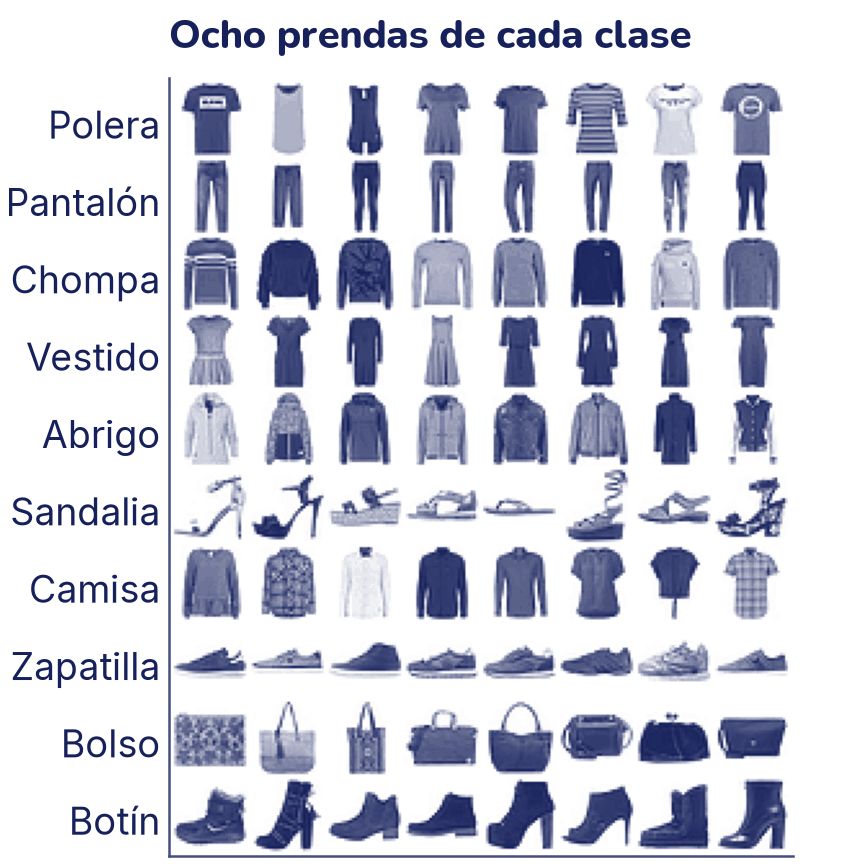

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from torchvision.utils import make_grid

# Del blanco al color "C0": la prenda oscura sobre fondo claro
tinta = LinearSegmentedColormap.from_list("tinta", ["white", "C0"])

filas = []
for k in range(10):
    # Las posiciones de las primeras 8 fotos de la clase k: nonzero da
    # los índices donde vale True, en forma (n, 1), y squeeze(1) quita
    # esa columna de más
    indices = (datos_ent.targets == k).nonzero().squeeze(1)[:8]
    filas.append(datos_ent.data[indices])     # (8, 28, 28)
lote = torch.cat(filas).unsqueeze(1)          # (80, 1, 28, 28)
mosaico = make_grid(lote, nrow=8, padding=2)  # (3, 302, 242)
print("Lote:", tuple(lote.shape), "  mosaico:", tuple(mosaico.shape))

plt.figure(figsize=(4.8, 4.8))
plt.imshow(mosaico[0], cmap=tinta)            # un canal basta
plt.yticks([16 + 30 * k for k in range(10)], NOMBRES)
plt.xticks([])
plt.grid(False)
plt.title("Ocho prendas de cada clase")
plt.show()

Mira el mosaico con ojos de modelo. Pantalones, bolsos y calzados tienen siluetas muy propias. En cambio poleras, chompas, abrigos y camisas se parecen mucho entre sí: la diferencia está en las mangas, el cuello o los botones, detalles que a 28 × 28 casi se pierden. Ahí se va a equivocar el modelo.

## Datos listos para entrenar: Dataset y DataLoader

Antes de entrenar hay que preparar cuatro cosas:

1. **Números decimales con un eje de canales.** Pasamos los enteros de 0 a 255 a decimales de 0 a 1 y agregamos el eje de canales con `unsqueeze(1)`: (60 000, 28, 28) se vuelve (60 000, 1, 28, 28), la forma de un lote de imágenes en PyTorch.
2. **Una partición de validación** (tema 7). Las 60 000 fotos de entrenamiento se reparten al azar en 50 000 para entrenar y 10 000 para validar, es decir, para vigilar el entrenamiento y tomar decisiones. Las 10 000 de prueba no se tocan hasta el final.
3. **Estandarizar** (tema 6), con el promedio y la desviación de las fotos de entrenamiento. Igual que en la regresión, el descenso de gradiente baja más rápido cuando las entradas están centradas en cero.
4. **Lotes.** En lugar de calcular el gradiente con las 50 000 fotos a la vez (lento) o con una sola (muy ruidoso), se usa un **lote** pequeño de fotos al azar en cada paso. Una **época** es una pasada completa por todos los lotes.

In [ ]:
# De 0–255 a 0–1, con un eje de canales: (N, 1, 28, 28)
X = datos_ent.data.float().div(255).unsqueeze(1)
X_pru = datos_pru.data.float().div(255).unsqueeze(1)
y_pru = datos_pru.targets

# 50 000 fotos para entrenar y 10 000 para validar, al azar
orden = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
i_val, i_ent = orden[:10000], orden[10000:]
X_ent, y_ent = X[i_ent], datos_ent.targets[i_ent]
X_val, y_val = X[i_val], datos_ent.targets[i_val]

# Estandarizar con lo que se aprende del entrenamiento
media, desviacion = X_ent.mean(), X_ent.std()
X_ent = (X_ent - media) / desviacion
X_val = (X_val - media) / desviacion
X_pru = (X_pru - media) / desviacion
print(f"Media {media:.3f}, desviación {desviacion:.3f}")
print("Entrenar:", tuple(X_ent.shape))
print("Validar: ", tuple(X_val.shape))
print("Prueba:  ", tuple(X_pru.shape))

Media 0.286, desviación 0.353
Entrenar: (50000, 1, 28, 28)
Validar:  (10000, 1, 28, 28)
Prueba:   (10000, 1, 28, 28)


Ahora los dos ayudantes de PyTorch para los datos:

- Un **`Dataset`** es cualquier objeto que sabe dos cosas: cuántos ejemplos tiene (`len`) y cómo darte el ejemplo número *i* (`dataset[i]`, que devuelve la entrada y su etiqueta). `TensorDataset` arma uno a partir de tensores que ya tienes. Los `datasets` de `torchvision` también son `Dataset`, y en los ejercicios vas a escribir uno propio.
- Un **`DataLoader`** recorre un `Dataset` por lotes. Con `shuffle=True` los mezcla al azar en cada época; el `generator` con semilla hace que esa mezcla sea siempre la misma.

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

conjunto_ent = TensorDataset(X_ent, y_ent)
imagen, etiqueta = conjunto_ent[0]
print("Un ejemplo:", tuple(imagen.shape), "->", NOMBRES[etiqueta])

cargador_ent = DataLoader(conjunto_ent, batch_size=128, shuffle=True,
                          generator=torch.Generator().manual_seed(0))
cargador_val = DataLoader(TensorDataset(X_val, y_val), batch_size=1000)
cargador_pru = DataLoader(TensorDataset(X_pru, y_pru), batch_size=1000)

# iter prepara el recorrido de los lotes y next pide el primero
x_lote, y_lote = next(iter(cargador_ent))
print("Un lote:", tuple(x_lote.shape), tuple(y_lote.shape))
print("Lotes por época:", len(cargador_ent))

Un ejemplo: (1, 28, 28) -> Vestido
Un lote: (128, 1, 28, 28) (128,)
Lotes por época: 391


Con lotes de 128 fotos, una época son 391 pasos de descenso de gradiente: 390 lotes completos y uno final con las 80 fotos que sobran (50 000 = 390 · 128 + 80). Los cargadores de validación y prueba no mezclan nada, porque solo se usan para medir, y usan lotes más grandes porque medir no necesita gradientes y gasta poca memoria.

Podríamos haberle pedido a `torchvision` que convierta cada foto al vuelo (con `transform=transforms.ToTensor()`), y así lo vas a ver en muchos ejemplos. Convertir las 60 000 de una vez, como hicimos, hace que cada época corra varias veces más rápido en una CPU.

## El modelo: una clase de `nn.Module`

Nuestra red es un MLP como los del tema 16: aplanar cada foto en 784 números, una capa oculta de 128 neuronas con ReLU y una capa de salida de 10 neuronas, una por clase. En PyTorch, un modelo es una clase que **hereda** de `nn.Module`. Heredar es partir de un molde que ya trae funciones hechas: al escribir `class RedPrendas(nn.Module):`, la clase nueva recibe todo lo de `nn.Module` (guardar los parámetros, `.to()`, `.train()`, `.eval()`, `.parameters()`) y solo agrega lo propio. La primera línea de su `__init__` es siempre `super().__init__()`, que prepara esa parte heredada; sin ella, PyTorch no puede registrar las capas. Además, la clase define dos métodos:

- `__init__` crea las capas (y con ellas los parámetros);
- `forward` dice cómo pasa un lote por las capas. Al escribir `modelo(x)`, PyTorch llama a `forward(x)`.

In [ ]:
class RedPrendas(nn.Module):
    def __init__(self):
        super().__init__()
        self.aplanar = nn.Flatten()   # (N, 1, 28, 28) -> (N, 784)
        self.oculta = nn.Linear(784, 128)
        self.salida = nn.Linear(128, 10)

    def forward(self, x):
        x = self.aplanar(x)
        x = torch.relu(self.oculta(x))
        return self.salida(x)         # 10 puntajes por foto: (N, 10)


torch.manual_seed(0)
modelo = RedPrendas().to(device)
print(modelo)
print("Parámetros:", sum(p.numel() for p in modelo.parameters()))
salida = modelo(x_lote.to(device))
print("Entrada:", tuple(x_lote.shape), "  salida:", tuple(salida.shape))

RedPrendas(
  (aplanar): Flatten(start_dim=1, end_dim=-1)
  (oculta): Linear(in_features=784, out_features=128, bias=True)
  (salida): Linear(in_features=128, out_features=10, bias=True)
)
Parámetros: 101770
Entrada: (128, 1, 28, 28)   salida: (128, 10)


Los parámetros son 784 · 128 + 128 = 100 480 de la capa oculta (un peso por cada par entrada-neurona y un término independiente *b* por neurona) más 128 · 10 + 10 = 1290 de la salida: 101 770 en total. `.to(device)` lleva el modelo a la GPU si la hay; en una CPU no hace nada.

El `nn.Flatten()` de la primera capa no es un detalle. Mira qué pasa si le das el lote de imágenes directo a una capa lineal:

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
capa = nn.Linear(784, 128)
capa(x_lote)

Traceback (most recent call last):
  ...
RuntimeError: mat1 and mat2 shapes cannot be multiplied (3584x28 and 784x128)


El mensaje se lee así: `nn.Linear` multiplica por su última dimensión, que aquí es el ancho, 28. PyTorch tomó las 128 · 1 · 28 = 3584 filas de 28 píxeles e intentó multiplicarlas por una matriz que espera 784 entradas. Cuando veas `shapes cannot be multiplied`, imprime las formas: casi siempre falta un `flatten` o sobra un eje.

Para redes que son solo una fila de capas, `nn.Sequential` evita escribir la clase. Esta red es la misma (con sus propios pesos al azar):

In [ ]:
otra = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                     nn.Linear(128, 10))
print(tuple(otra(x_lote).shape))

(128, 10)


### Logits y entropía cruzada

Las 10 salidas de la red son **logits**: puntajes sueltos, positivos o negativos, que no suman 1. En el tema 8 viste que **softmax** los convierte en probabilidades y que la **entropía cruzada** castiga dar poca probabilidad a la clase correcta. `nn.CrossEntropyLoss` hace las dos cosas juntas: **recibe logits** y aplica el softmax por dentro. Por eso la red no termina en softmax.

In [ ]:
funcion_perdida = nn.CrossEntropyLoss()
perdida = funcion_perdida(salida, y_lote.to(device))
print(f"Pérdida sin entrenar: {perdida.item():.3f}")
print(f"ln(10) =              {np.log(10):.3f}")

probabilidades = torch.softmax(salida, dim=1)
print("Probabilidades de la primera foto:")
print(np.round(probabilidades[0].detach().cpu().numpy(), 2))

Pérdida sin entrenar: 2.345
ln(10) =              2.303
Probabilidades de la primera foto:
[0.07 0.15 0.09 0.09 0.08 0.13 0.07 0.14 0.04 0.12]


La red sin entrenar reparte la probabilidad casi en partes iguales: cada clase recibe entre 0,04 y 0,15. La entropía cruzada de dar 1/10 a la clase correcta es −log(1/10) = log(10) ≈ 2,303, con el logaritmo natural, el que en el colegio se escribe ln (es el que calculan `np.log` y PyTorch), y la pérdida da casi eso, 2,345. Es un buen control: si una red de 10 clases sin entrenar empieza con una pérdida muy distinta de 2,3, algo está mal armado. (El `.detach()` saca el tensor del grafo, porque NumPy no sabe de gradientes, y `.cpu()` lo trae de la GPU si estaba allá.)

## El bucle de entrenamiento, a mano

Ya tenemos todas las piezas. El bucle es el mismo de la recta, con dos cambios: recorre los lotes del `DataLoader` y mueve cada lote al mismo dispositivo que el modelo. Hagamos una sola época:

In [ ]:
torch.manual_seed(0)
modelo = RedPrendas().to(device)
funcion_perdida = nn.CrossEntropyLoss()
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)

modelo.train()                        # modo entrenamiento
for paso, (x, y) in enumerate(cargador_ent):
    x, y = x.to(device), y.to(device)  # al dispositivo del modelo
    optimizador.zero_grad()           # 1. gradientes en cero
    salida = modelo(x)                # 2. adelante: logits (128, 10)
    perdida = funcion_perdida(salida, y)  # 3. la pérdida del lote
    perdida.backward()                # 4. atrás: los gradientes
    optimizador.step()                # 5. un paso en contra
    if paso % 100 == 0:
        print(f"Paso {paso:3d}: pérdida del lote {perdida.item():.3f}")

Paso   0: pérdida del lote 2.342
Paso 100: pérdida del lote 0.554
Paso 200: pérdida del lote 0.414
Paso 300: pérdida del lote 0.532


La pérdida empieza en 2,3 (adivinar al azar) y en una sola época baja a alrededor de 0,5. Salta un poco de un lote a otro porque cada lote trae fotos distintas. Para saber si el modelo aprendió de verdad hay que medirlo con fotos que no usó para entrenar, las de validación. Medir tiene sus propias reglas:

- `modelo.eval()` pone el modelo en **modo evaluación**. Esta red se comporta igual en los dos modos, pero algunas capas que verás en el tema 19 (*dropout* y la normalización por lotes) actúan distinto al entrenar y al evaluar. La costumbre es siempre `train()` antes de entrenar y `eval()` antes de medir.
- `torch.no_grad()` le dice a PyTorch que no arme el grafo: para medir no hacen falta gradientes, y así se gasta menos memoria y tiempo.
- La clase predicha es la de mayor logit: `argmax(dim=1)`, una por foto.

In [ ]:
modelo.eval()                         # modo evaluación
aciertos = 0
with torch.no_grad():                 # sin grafo: solo medimos
    for x, y in cargador_val:
        x, y = x.to(device), y.to(device)
        predicho = modelo(x).argmax(dim=1)
        aciertos += (predicho == y).sum().item()
print(f"Exactitud de validación tras una época: "
      f"{aciertos / len(X_val):.3f}")

Exactitud de validación tras una época: 0.828


Después de una sola pasada por las fotos, el modelo ya acierta 83 de cada 100 prendas que no usó para aprender.

## La función `entrenar()`: el bucle que usarás en toda la ruta

Ese bucle de entrenar una época y después medir se repite igual en cada modelo, sea una red de prendas, una red convolucional o un modelo de texto. En lugar de copiarlo una y otra vez, lo guardamos en dos funciones:

- `evaluar` mide un modelo sobre un cargador y devuelve la pérdida media y la exactitud.
- `entrenar` repite épocas: entrena con todos los lotes, mide con la validación, guarda los números en un **historial** y, si se le pide, los imprime.

**Esta es la función del bucle de entrenamiento de la ruta.** Los temas que siguen (desde el 19, que la usa para comparar optimizadores) la copian tal cual, así que vale la pena entenderla línea por línea:

In [ ]:
import torch
from torch import nn


def evaluar(modelo, cargador, funcion_perdida, dispositivo="cpu"):
    """Pérdida media y exactitud de `modelo` sobre `cargador`."""
    modelo.eval()
    suma, aciertos, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            salida = modelo(x)
            suma += funcion_perdida(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
    return suma / total, aciertos / total


def entrenar(modelo, cargador_ent, cargador_val, epocas, optimizador,
             funcion_perdida=None, planificador=None, dispositivo="cpu",
             mostrar=True):
    """Entrena `modelo` y devuelve el historial de cada época."""
    if funcion_perdida is None:
        funcion_perdida = nn.CrossEntropyLoss()
    modelo.to(dispositivo)
    historial = {"perdida_ent": [], "exactitud_ent": [],
                 "perdida_val": [], "exactitud_val": []}
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma, aciertos, total = 0.0, 0, 0
        for x, y in cargador_ent:
            x, y = x.to(dispositivo), y.to(dispositivo)
            optimizador.zero_grad()
            salida = modelo(x)
            perdida = funcion_perdida(salida, y)
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
        if planificador is not None:
            planificador.step()
        perdida_val, exactitud_val = evaluar(
            modelo, cargador_val, funcion_perdida, dispositivo)
        historial["perdida_ent"].append(suma / total)
        historial["exactitud_ent"].append(aciertos / total)
        historial["perdida_val"].append(perdida_val)
        historial["exactitud_val"].append(exactitud_val)
        if mostrar:
            print(f"Época {epoca}: pérdida {suma / total:.3f}, "
                  f"validación {perdida_val:.3f}, "
                  f"exactitud de validación {exactitud_val:.3f}")
    return historial

Lo que conviene notar:

- **El corazón es el bucle a mano de arriba**: `zero_grad`, adelante, pérdida, `backward`, `step`, con `train()` al entrenar y `eval()` más `no_grad()` al medir.
- **`perdida.item() * len(y)`.** La pérdida de un lote es un promedio. Para promediar bien toda la época se multiplica por el tamaño del lote y al final se divide por el total, porque el último lote puede ser más chico. `.item()` convierte un tensor de un solo número en un número de Python (y lo trae de la GPU si estaba allá).
- **La exactitud de entrenamiento se mide mientras el modelo cambia.** Cada lote se mide con los parámetros de ese momento, así que es un promedio a lo largo de la época, no la exactitud del modelo final. Por eso, en las primeras épocas, puede salir por debajo de la de validación.
- **Valores por defecto.** Si no le das una `funcion_perdida`, usa la entropía cruzada, la de clasificación. `planificador` es para cambiar la tasa de aprendizaje en cada época; lo verás en el tema 19 y aquí queda en `None`. Con `mostrar=False` no imprime nada.
- **`dispositivo`** recibe el `device` del principio. La función mueve el modelo y cada lote ahí, así que el mismo código corre en CPU o en GPU.
- **El historial** es un diccionario con cuatro listas, un número por época. Sirve para dibujar las curvas.

Entrenemos una red nueva diez épocas:

In [ ]:
torch.manual_seed(0)
modelo = RedPrendas()
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)
historial = entrenar(modelo, cargador_ent, cargador_val, epocas=10,
                     optimizador=optimizador, dispositivo=device)

Época 1: pérdida 0.560, validación 0.451, exactitud de validación 0.838
Época 2: pérdida 0.402, validación 0.422, exactitud de validación 0.848
Época 3: pérdida 0.361, validación 0.395, exactitud de validación 0.859
Época 4: pérdida 0.337, validación 0.369, exactitud de validación 0.866
Época 5: pérdida 0.318, validación 0.354, exactitud de validación 0.874
Época 6: pérdida 0.301, validación 0.362, exactitud de validación 0.871
Época 7: pérdida 0.290, validación 0.360, exactitud de validación 0.871
Época 8: pérdida 0.275, validación 0.340, exactitud de validación 0.878
Época 9: pérdida 0.266, validación 0.332, exactitud de validación 0.882
Época 10: pérdida 0.257, validación 0.369, exactitud de validación 0.867


Diez épocas son 3910 pasos de descenso de gradiente. En una CPU cada época tarda unos pocos segundos; con una GPU, menos. Dibujemos el historial:

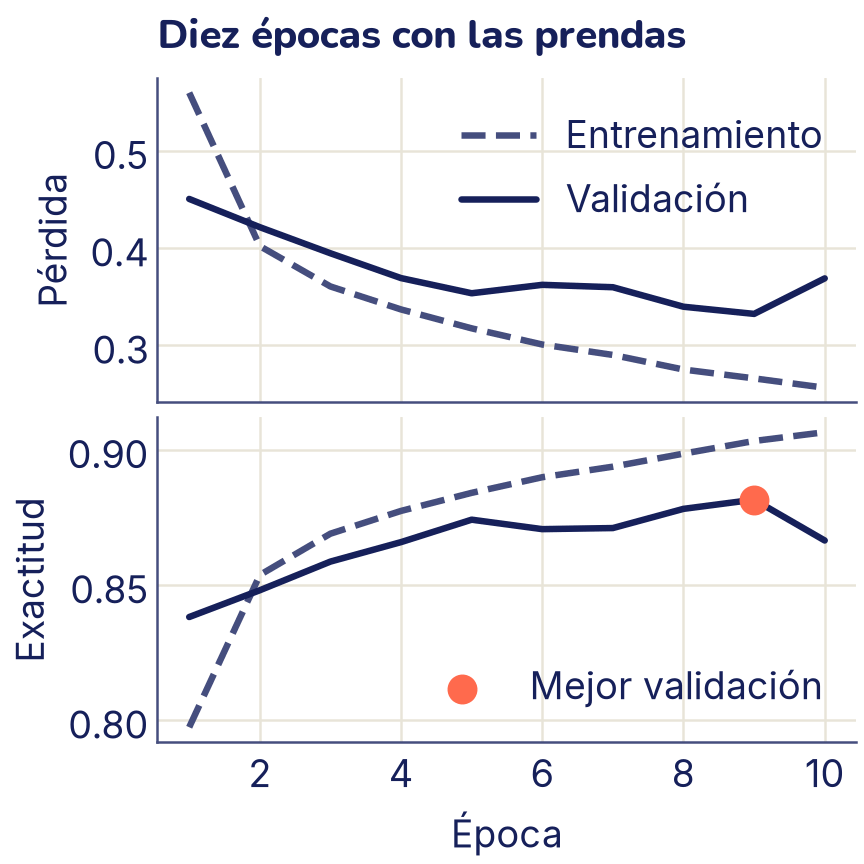

In [ ]:
epocas = range(1, len(historial["perdida_ent"]) + 1)
mejor = int(np.argmax(historial["exactitud_val"]))   # índice desde 0

fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(4.8, 4.8),
                                    sharex=True)
# Entrenamiento a rayas, para distinguirlo de validación
arriba.plot(epocas, historial["perdida_ent"], color="C2", linestyle="--",
            label="Entrenamiento")
arriba.plot(epocas, historial["perdida_val"], color="C0",
            label="Validación")
arriba.set_ylabel("Pérdida")
arriba.set_title("Diez épocas con las prendas")
arriba.legend()
abajo.plot(epocas, historial["exactitud_ent"], color="C2", linestyle="--")
abajo.plot(epocas, historial["exactitud_val"], color="C0")
abajo.scatter([mejor + 1], [historial["exactitud_val"][mejor]],
              color="C1", s=120, zorder=3, label="Mejor validación")
abajo.set_xlabel("Época")
abajo.set_ylabel("Exactitud")
abajo.legend()
plt.show()

Las curvas cuentan tres cosas:

- **La pérdida de entrenamiento baja sin parar**, de 0,560 a 0,257: el descenso de gradiente hace su trabajo con las fotos que ve.
- **La validación mejora casi siempre, pero a saltos.** Su mejor exactitud es 0,882, en la época 9, y en la época 10 baja a 0,867 mientras la pérdida de validación sube de 0,332 a 0,369. Cada paso usa un lote de solo 128 fotos, así que el descenso es ruidoso (por eso se llama *estocástico*), y el modelo de la última época no tiene por qué ser el mejor. En el tema 19 vas a ver cómo suavizar esos saltos y cómo quedarte con el modelo de la mejor época (la parada temprana).
- **La brecha entre entrenamiento y validación empieza a abrirse** hacia el final: el modelo ya acierta más con las fotos que conoce que con las nuevas. Es el sobreajuste del tema 7, todavía leve.

## La prueba final: matriz de confusión

La validación sirvió para vigilar el entrenamiento. Ahora, con el modelo ya decidido, medimos una sola vez con las 10 000 fotos de prueba, que el modelo nunca vio y con las que no tomamos ninguna decisión:

In [ ]:
perdida_pru, exactitud_pru = evaluar(modelo, cargador_pru,
                                     nn.CrossEntropyLoss(), device)
print(f"Prueba: pérdida {perdida_pru:.3f}, exactitud {exactitud_pru:.3f}")

# Las predicciones de las 10 000 fotos de prueba, en orden
modelo.eval()
with torch.no_grad():
    predicho = torch.cat([modelo(x.to(device)).argmax(dim=1).cpu()
                          for x, _ in cargador_pru])
print("Predicciones:", tuple(predicho.shape))

Prueba: pérdida 0.385, exactitud 0.861
Predicciones: (10000,)


La exactitud de prueba es 0,861: el modelo acierta 86 de cada 100 prendas que nunca vio. Es casi igual a la validación del modelo que usamos, el de la época 10 (0,867). La mejor validación, 0,882, era de otro modelo, el de la época 9, que no guardamos. Para comparar, adivinar al azar acertaría 10 de cada 100.

Un solo número esconde **dónde** se equivoca el modelo. La matriz de confusión del tema 9 lo muestra: cada fila es una clase real, cada columna es lo que dijo el modelo, y fuera de la diagonal están los errores. Con 10 clases tiene 100 celdas:

Lo que más confunde: Camisa -> Polera, 242 veces


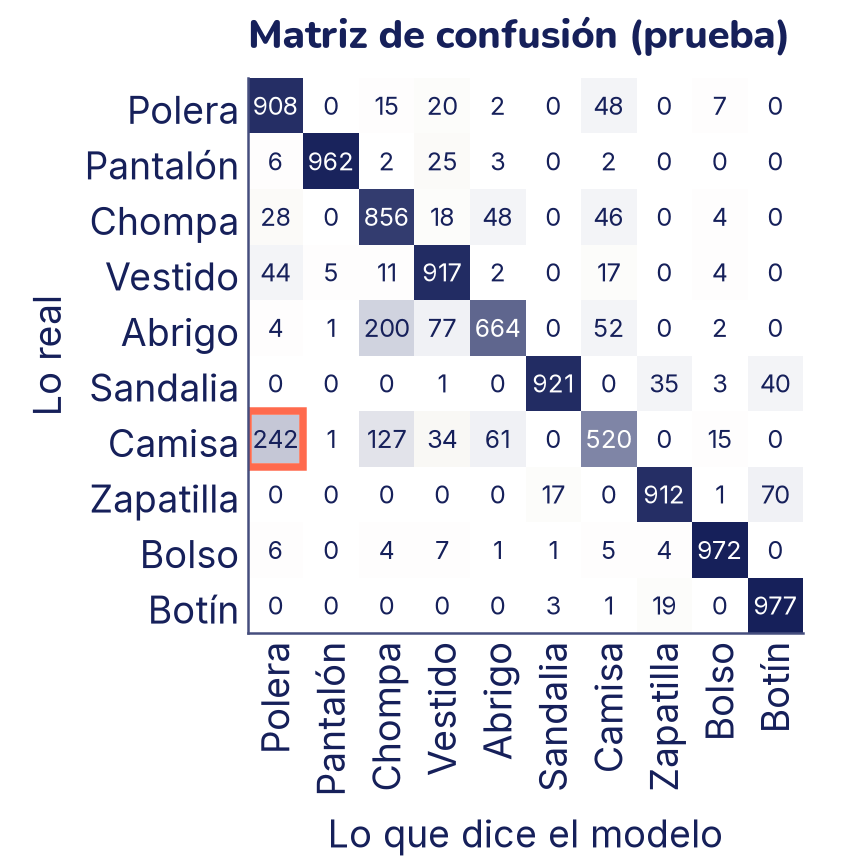

In [ ]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(y_pru, predicho)

# La confusión más frecuente: la celda más alta fuera de la diagonal
fuera = matriz.copy()
np.fill_diagonal(fuera, 0)
# argmax da la posición en la matriz aplanada; unravel_index la
# convierte en (fila, columna)
real, dice = np.unravel_index(fuera.argmax(), fuera.shape)
print(f"Lo que más confunde: {NOMBRES[real]} -> {NOMBRES[dice]}, "
      f"{matriz[real, dice]} veces")

plt.figure(figsize=(4.8, 4.8))
plt.imshow(matriz, cmap=tinta)
for i in range(10):
    for j in range(10):
        plt.text(j, i, matriz[i, j], ha="center", va="center",
                 fontsize=10, color="white" if matriz[i, j] > 500 else "C0")
plt.gca().add_patch(plt.Rectangle((dice - 0.5, real - 0.5), 1, 1,
                                  fill=False, edgecolor="C1", linewidth=3))
plt.xticks(range(10), NOMBRES, rotation=90)
plt.yticks(range(10), NOMBRES)
plt.xlabel("Lo que dice el modelo")
plt.ylabel("Lo real")
plt.title("Matriz de confusión (prueba)")
plt.grid(False)
plt.show()

La exactitud de cada clase es su número en la diagonal dividido por el total de su fila:

In [ ]:
por_clase = matriz.diagonal() / matriz.sum(axis=1)
for k in np.argsort(por_clase):       # de la peor a la mejor
    print(f"{NOMBRES[k]:10s} {por_clase[k]:.2f}")

Camisa     0.52
Abrigo     0.66
Chompa     0.86
Polera     0.91
Zapatilla  0.91
Vestido    0.92
Sandalia   0.92
Pantalón   0.96
Bolso      0.97
Botín      0.98


La matriz confirma lo que sugería el mosaico. Pantalones, bolsos y botines aciertan el 96 % o más. Los errores se juntan en dos familias de prendas que se parecen: la ropa de la parte de arriba del cuerpo (la camisa se confunde con la polera 242 veces y con la chompa 127; el abrigo, con la chompa 200 veces) y el calzado (70 zapatillas tomadas por botines). **La camisa es la peor clase: solo acierta el 52 %**, apenas la mitad. Casi nunca confunde una prenda con otra muy distinta: ningún pantalón fue tomado por zapatilla.

### Mirar los errores

Las cifras dicen cuánto se equivoca el modelo; mirar los errores dice **por qué**. Veamos cuatro fotos de prueba mal clasificadas:

Fotos mal clasificadas: 1391 de 10000


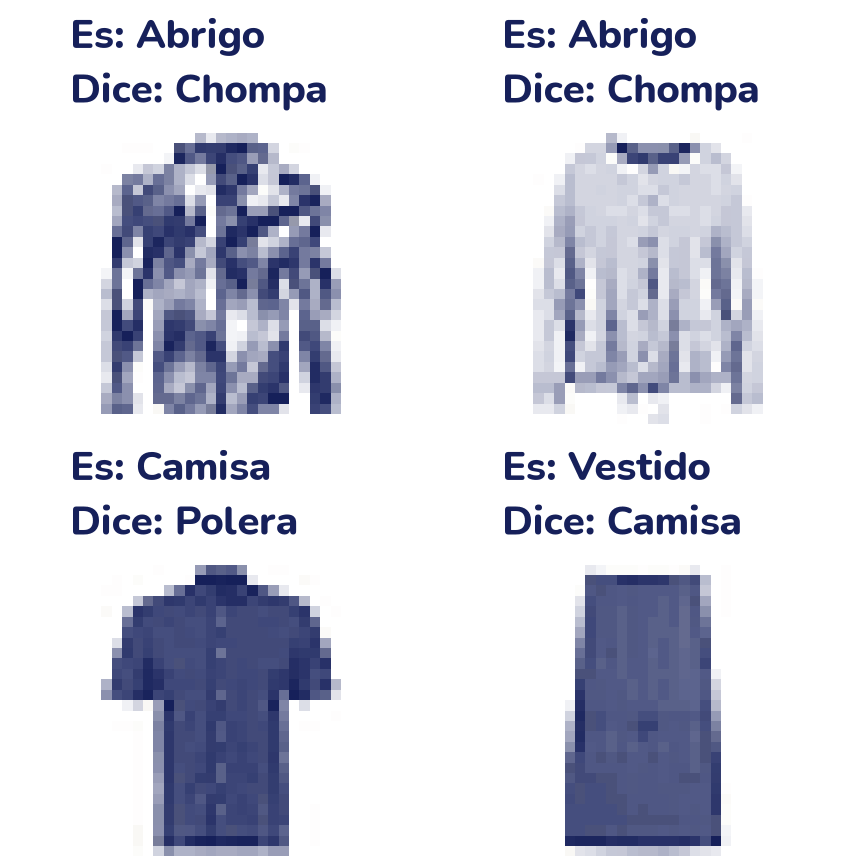

In [ ]:
errores = (predicho != y_pru).nonzero().squeeze(1)
print("Fotos mal clasificadas:", len(errores), "de", len(y_pru))

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, k in zip(ejes.flat, errores[:4]):
    eje.imshow(datos_pru.data[k], cmap=tinta)
    eje.set_title(f"Es: {NOMBRES[y_pru[k]]}\n"
                  f"Dice: {NOMBRES[predicho[k]]}")
    eje.axis("off")
plt.show()

De 10 000 fotos, 1391 están mal clasificadas. Las cuatro primeras son errores comprensibles: los dos abrigos tienen la misma silueta de manga larga que una chompa, la camisa de manga corta parece una polera, y el vestido recto se ve como un rectángulo sin forma. Fíjate en que nuestra red **aplana** la foto en 784 números sueltos: no sabe que dos píxeles vecinos están juntos, y los detalles que separan una camisa de una polera (el cuello, la fila de botones) son justo detalles de forma local. Las redes convolucionales del tema 20 miran la imagen por vecindarios, justamente para captar ese tipo de detalles.

## Guardar y cargar un modelo

Entrenar cuesta tiempo; usar el modelo entrenado, casi nada. Por eso se guardan los parámetros en un archivo. El **`state_dict`** de un modelo es un diccionario con el nombre y el tensor de cada parámetro. Se guarda con `torch.save` y se carga en un modelo nuevo de la **misma clase** con `load_state_dict`:

In [ ]:
torch.save(modelo.state_dict(), "prendas.pt")
for nombre, tensor in modelo.state_dict().items():
    print(f"{nombre:15s} {tuple(tensor.shape)}")

nuevo = RedPrendas()                  # pesos al azar...
nuevo.load_state_dict(torch.load("prendas.pt", map_location="cpu"))
nuevo.eval()                          # ...y ahora, los entrenados

una = X_pru[0]                        # una foto: (1, 28, 28)
with torch.no_grad():
    probabilidades = torch.softmax(nuevo(una.unsqueeze(0)), dim=1)
k = probabilidades.argmax().item()
print(f"Predice {NOMBRES[k]} con probabilidad "
      f"{probabilidades[0, k]:.2f}; es {NOMBRES[y_pru[0]]}")

oculta.weight   (128, 784)
oculta.bias     (128,)
salida.weight   (10, 128)
salida.bias     (10,)
Predice Botín con probabilidad 1.00; es Botín


El archivo guarda solo números: para usarlo necesitas la clase `RedPrendas`, que dice cómo se conectan. `map_location="cpu"` permite cargar en una computadora sin GPU un modelo guardado en Colab con GPU. Para predecir, las mismas tres reglas de siempre: `eval()`, `no_grad()` y un eje de lote con `unsqueeze(0)`.

## CPU o GPU

Una **GPU** (tarjeta gráfica) hace miles de multiplicaciones a la vez, justo lo que necesita una red. En Colab se activa en el menú *Entorno de ejecución → Cambiar tipo de entorno de ejecución*, eligiendo una GPU; después hay que volver a correr el cuaderno desde el principio. Si no hay GPU disponible (Colab la presta por un tiempo limitado), todo el código de este tema funciona igual en CPU, solo que más lento.

Para que el mismo código sirva en los dos casos:

- Se elige el dispositivo una vez, al principio: `device = "cuda" if torch.cuda.is_available() else "cpu"`.
- El **modelo** va al dispositivo con `modelo.to(device)` (la función `entrenar` ya lo hace).
- **Cada lote** va al mismo dispositivo antes de entrar al modelo: `x, y = x.to(device), y.to(device)`. Si el modelo está en la GPU y los datos en la CPU, PyTorch se detiene con un error que dice que esperaba todos los tensores en el mismo dispositivo.
- Para pasar un resultado a NumPy o a matplotlib, primero vuelve a la CPU: `.cpu()`, o `.item()` si es un solo número.

Con una red tan pequeña como la nuestra, la GPU no gana mucho: buena parte del tiempo se va en repartir los lotes. Con las redes convolucionales del tema 20, la diferencia ya se nota.

### Reproducibilidad

Una red empieza con pesos al azar y ve los lotes en orden al azar. Para que dos ejecuciones den lo mismo, fija las dos fuentes de azar: `torch.manual_seed(0)` antes de crear el modelo, y un `generator` con semilla en cada `DataLoader` que mezcla. En este tema, correr el cuaderno dos veces en la misma computadora da exactamente los mismos números. En otra computadora, y sobre todo en una GPU, los últimos decimales pueden cambiar, porque el orden en que se suman miles de números en paralelo cambia el redondeo. Por eso tus números pueden diferir un poco de los de esta página.

## Lo que aprendiste y lo que sigue

- Un **tensor** es un arreglo de NumPy con dos cosas más: un dispositivo (CPU o GPU) y la capacidad de recordar operaciones para calcular gradientes. Las redes trabajan con lotes de forma (N, canales, alto, ancho), y `reshape`, `permute`, `flatten`, `unsqueeze`, `cat` y `stack` cambian esa forma sin cambiar los números.
- **Autograd** es tu clase `Valor` del tema 17 hecha a escala: `requires_grad=True` arma el grafo, `.backward()` llena los `.grad`, y los gradientes se acumulan hasta que los pones en cero.
- Un modelo es una clase de **`nn.Module`** con `__init__` (las capas) y `forward` (el camino de los datos). `nn.CrossEntropyLoss` recibe logits, no probabilidades.
- **`Dataset`** da ejemplos sueltos y **`DataLoader`** los agrupa en lotes mezclados. Una época es una pasada por todos los lotes.
- El **bucle de entrenamiento** es siempre `zero_grad`, adelante, pérdida, `backward`, `step`; para medir, `eval()` y `no_grad()`. Las funciones **`entrenar()`** y **`evaluar()`** lo empaquetan, y nuestro MLP de 101 770 parámetros llega a un 86 % de exactitud en la prueba de FashionMNIST.
- `state_dict`, `torch.save` y `load_state_dict` guardan y recuperan un modelo; `device` y las semillas hacen que el mismo código corra igual en cualquier lado.

Desde aquí, cada tema de redes reutiliza `entrenar()` y cambia otra cosa. En el tema 19 vas a cambiar el **optimizador** y la regularización, y a entender por qué las curvas de validación saltan. En el tema 20, el **modelo**: una red convolucional que mira las fotos como imágenes en lugar de aplanarlas.

# Ejercicios

## Antes de empezar

Varios ejercicios usan lo que construiste en la teoría: `torch`, `nn`, `np`, `plt`, `device`, los tensores `X_ent`, `y_ent`, `X_val`, `y_val`, `X_pru` y `y_pru`, `conjunto_ent`, los cargadores `cargador_ent`, `cargador_val` y `cargador_pru`, la clase `RedPrendas`, el `modelo` entrenado con su `historial`, las funciones `entrenar` y `evaluar`, la lista `NOMBRES` y las predicciones de prueba `predicho`. Corre primero todo el código de la teoría, en orden. Si cierras el cuaderno, vuelve a correrlo desde el principio.

## Ejercicios

### 1. Veinte formas

Sin computadora, escribe la forma del resultado de cada expresión, o «error» si no se puede calcular. Los tensores son `a = torch.zeros(64, 1, 28, 28)` (un lote de fotos), `b = torch.zeros(3, 4)` y `c = torch.zeros(5)`.

1. `a.flatten(1)`
2. `a.squeeze(1)`
3. `a.permute(0, 2, 3, 1)`
4. `a.sum(dim=0)`
5. `a.mean(dim=(2, 3))`
6. `a[0]`
7. `a[:10]`
8. `a.view(64, -1)`
9. `a.reshape(-1, 28)`
10. `nn.Linear(784, 10)(a.flatten(1))`
11. `b.T`
12. `b.unsqueeze(0)`
13. `b.unsqueeze(-1)`
14. `b.sum(dim=1)`
15. `b.sum(dim=1, keepdim=True)`
16. `torch.cat([b, b])`
17. `torch.cat([b, b], dim=1)`
18. `torch.stack([b, b])`
19. `b @ torch.zeros(4, 2)`
20. `c.unsqueeze(1) * c`

<details>
<summary>Respuesta</summary>

Ninguna da error. Las que más se fallan son la 5 (promediar los ejes 2 y 3 deja uno por foto y por canal), la 9 (el −1 junta todo lo demás: 64 · 1 · 28 = 1792 filas de 28), la 15 (`keepdim=True` deja el eje con tamaño 1 en lugar de borrarlo) y la 20, que es broadcasting (tema 3): (5, 1) por (5,) se estira a (5, 5). Compruébalo:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
a = torch.zeros(64, 1, 28, 28)
b = torch.zeros(3, 4)
c = torch.zeros(5)
resultados = [
    ("a.flatten(1)", a.flatten(1)),
    ("a.squeeze(1)", a.squeeze(1)),
    ("a.permute(0, 2, 3, 1)", a.permute(0, 2, 3, 1)),
    ("a.sum(dim=0)", a.sum(dim=0)),
    ("a.mean(dim=(2, 3))", a.mean(dim=(2, 3))),
    ("a[0]", a[0]),
    ("a[:10]", a[:10]),
    ("a.view(64, -1)", a.view(64, -1)),
    ("a.reshape(-1, 28)", a.reshape(-1, 28)),
    ("nn.Linear(784, 10)(a.flatten(1))",
     nn.Linear(784, 10)(a.flatten(1))),
    ("b.T", b.T),
    ("b.unsqueeze(0)", b.unsqueeze(0)),
    ("b.unsqueeze(-1)", b.unsqueeze(-1)),
    ("b.sum(dim=1)", b.sum(dim=1)),
    ("b.sum(dim=1, keepdim=True)", b.sum(dim=1, keepdim=True)),
    ("torch.cat([b, b])", torch.cat([b, b])),
    ("torch.cat([b, b], dim=1)", torch.cat([b, b], dim=1)),
    ("torch.stack([b, b])", torch.stack([b, b])),
    ("b @ torch.zeros(4, 2)", b @ torch.zeros(4, 2)),
    ("c.unsqueeze(1) * c", c.unsqueeze(1) * c),
]
for numero, (texto, t) in enumerate(resultados, start=1):
    print(f"{numero:2d}. {texto:33s} {tuple(t.shape)}")

### 2. Autograd contra tu lápiz

Sea *f* = *x*² · *y* + 3*y*, con *x* = 2 e *y* = −1.

a) Calcula a mano el valor de *f* y las derivadas parciales ∂*f*/∂*x* y ∂*f*/∂*y*.

b) Compruébalo con `requires_grad` y `.backward()`.

c) Con la clase `Valor` del tema 17, ¿qué tendrías que escribir para obtener lo mismo?

<details>
<summary>Respuesta</summary>

a) *f* = 4 · (−1) + 3 · (−1) = **−7**. Derivando: ∂*f*/∂*x* = 2*x*·*y* = 2 · 2 · (−1) = **−4** y ∂*f*/∂*y* = *x*² + 3 = 4 + 3 = **7**.

b)

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(-1.0, requires_grad=True)
f = x ** 2 * y + 3 * y
f.backward()
print("f =", f.item(), "  df/dx =", x.grad.item(),
      "  df/dy =", y.grad.item())

<details>
<summary>Respuesta (sigue)</summary>

c) Lo mismo con `Valor(2.0)` y `Valor(-1.0)` en lugar de los tensores, y la retropropagación de tu clase en lugar de `f.backward()`. Fíjate en que *y* aparece dos veces en la fórmula: su gradiente llega por dos caminos (*x*² y 3) y se suma, que es justo por qué tu motor usaba `+=`.

</details>

### 3. Gradientes que se acumulan

Predice qué imprime `tres_vueltas()` antes de llamarla. Después, di qué línea falta para que imprima siempre lo mismo, y en qué lugar de la función `entrenar` está esa línea.

In [ ]:
def tres_vueltas():
    w = torch.tensor(1.0, requires_grad=True)
    for vuelta in range(3):
        perdida = (3 * w) ** 2
        perdida.backward()
        print(w.grad.item())

In [ ]:
# @title Respuesta: código (doble clic para verlo)
tres_vueltas()

<details>
<summary>Respuesta</summary>

La pérdida es 9*w*², y su derivada es 18*w* = 18 cuando *w* = 1. Como `.backward()` **suma** al `.grad` que ya había, imprime 18, 36 y 54. Falta `w.grad.zero_()` (o, con un optimizador, `optimizador.zero_grad()`) antes de cada `backward`. En `entrenar` es la segunda línea dentro del bucle de los lotes, justo después de mover `x` e `y` al dispositivo.

</details>

### 4. Tu propio `Dataset`

Escribe una clase `PrendasEspejo` que herede de `torch.utils.data.Dataset` y que, a partir de unos tensores `X` e `y`, devuelva cada foto **volteada de izquierda a derecha** junto con su etiqueta. Pista: necesita `__init__`, `__len__` y `__getitem__`, métodos especiales como los del tema 17 (Python llama a `__len__` con `len(espejo)` y a `__getitem__` con `espejo[i]`), y `torch.flip(t, dims=[k])` voltea el tensor `t` a lo largo del eje `k`.

a) ¿En qué eje hay que voltear una foto de forma (1, 28, 28)?

b) Arma un `DataLoader` con las fotos de validación en espejo y comprueba la forma de un lote de 32.

c) Mide la exactitud del `modelo` de la teoría con esas fotos. ¿Sube, baja o queda igual? ¿Por qué?

<details>
<summary>Respuesta</summary>

a) En el eje 2, el ancho: la forma es (canales, alto, ancho).

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from torch.utils.data import Dataset


class PrendasEspejo(Dataset):
    """Las fotos de X, volteadas de izquierda a derecha, con su etiqueta."""

    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return torch.flip(self.X[i], dims=[2]), self.y[i]


espejo = PrendasEspejo(X_val, y_val)
imagen, etiqueta = espejo[0]
print(len(espejo), "fotos; la primera:", tuple(imagen.shape),
      NOMBRES[etiqueta])

x_lote, y_lote = next(iter(DataLoader(espejo, batch_size=32)))
print("Un lote:", tuple(x_lote.shape), tuple(y_lote.shape))

cargador_espejo = DataLoader(espejo, batch_size=1000)
_, exactitud_espejo = evaluar(modelo, cargador_espejo,
                              nn.CrossEntropyLoss(), device)
_, exactitud_normal = evaluar(modelo, cargador_val,
                              nn.CrossEntropyLoss(), device)
print(f"Exactitud normal {exactitud_normal:.3f}, "
      f"en espejo {exactitud_espejo:.3f}")

# ¿Qué clases sufren más con el espejo?
modelo.eval()
with torch.no_grad():
    predicho_espejo = torch.cat([modelo(x.to(device)).argmax(dim=1).cpu()
                                 for x, _ in cargador_espejo])
for k in range(10):
    es_k = y_val == k
    exactitud_k = (predicho_espejo[es_k] == k).float().mean().item()
    print(f"{NOMBRES[k]:10s} {exactitud_k:.2f}")

<details>
<summary>Respuesta (sigue)</summary>

c) **Baja mucho**, de 0,867 a 0,617, y casi todo por el calzado: el botín pasa de casi perfecto a 0,00, la sandalia queda en 0,24 y la zapatilla en 0,33. En FashionMNIST todos los zapatos miran hacia el mismo lado (mira el mosaico de la teoría), y el modelo aprendió esa dirección como parte de lo que es un zapato. Volteados, son algo que nunca vio. Las prendas casi simétricas, como poleras, pantalones y bolsos, apenas cambian. La lección: un modelo solo sabe de lo que hay en sus datos. Si en la vida real los zapatos pudieran mirar a los dos lados, habría que entrenar también con fotos volteadas; esa idea, la **aumentación de datos**, vuelve en los temas 19 y 20.

</details>

### 5. Cuatro errores en el bucle

Este bucle corre sin mostrar ningún mensaje de error, pero tiene cuatro errores. Encuéntralos comparándolo con `entrenar` y `evaluar`.

In [ ]:
def entrenar_con_errores(modelo, cargador, optimizador, epocas):
    funcion_perdida = nn.CrossEntropyLoss()
    modelo.to(device)
    for epoca in range(epocas):
        for x, y in cargador:
            salida = torch.softmax(modelo(x), dim=1)
            perdida = funcion_perdida(salida, y)
            perdida.backward()
            optimizador.step()


def exactitud_con_errores(modelo, cargador):
    aciertos = 0
    for x, y in cargador:
        aciertos += (modelo(x).argmax(dim=1) == y).sum().item()
    return aciertos / len(cargador.dataset)

<details>
<summary>Respuesta</summary>

1. **Falta `optimizador.zero_grad()`.** Los gradientes de todos los lotes anteriores se acumulan, y cada paso sigue una dirección vieja y cada vez más grande.
2. **Aplica softmax antes de `CrossEntropyLoss`.** La pérdida ya aplica softmax por dentro: así se aplica dos veces. Las probabilidades, entre 0 y 1, quedan como «logits» casi iguales entre sí, y los gradientes se vuelven pequeños.
3. **Evalúa sin `modelo.eval()` ni `torch.no_grad()`.** Además, el entrenamiento no llama a `modelo.train()`.
4. **No mueve los datos al dispositivo.** El modelo va a `device`, pero `x` e `y` no. En una CPU no pasa nada; en Colab con GPU, el código se detiene con un error que dice que se esperaban todos los tensores en el mismo dispositivo.

Los dos primeros se pueden medir. Esta función entrena una época con cada error por separado y mide la exactitud de validación:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def probar(con_zero_grad=True, con_softmax=False):
    """Una época con o sin cada error; devuelve la exactitud de validación."""
    torch.manual_seed(0)
    red = RedPrendas().to(device)
    optimizador = torch.optim.SGD(red.parameters(), lr=0.1)
    funcion_perdida = nn.CrossEntropyLoss()
    cargador = DataLoader(conjunto_ent, batch_size=128, shuffle=True,
                          generator=torch.Generator().manual_seed(0))
    red.train()
    for x, y in cargador:
        x, y = x.to(device), y.to(device)
        if con_zero_grad:
            optimizador.zero_grad()
        salida = red(x)
        if con_softmax:
            salida = torch.softmax(salida, dim=1)
        funcion_perdida(salida, y).backward()
        optimizador.step()
    return evaluar(red, cargador_val, funcion_perdida, device)[1]


print(f"Correcto:            {probar():.3f}")
print(f"Sin zero_grad:       {probar(con_zero_grad=False):.3f}")
print(f"Softmax de más:      {probar(con_softmax=True):.3f}")

<details>
<summary>Respuesta (sigue)</summary>

Sin `zero_grad`, la red casi no aprende: 0,215, apenas mejor que adivinar al azar (0,10). Con el softmax de más aprende, pero más despacio: 0,773 contra 0,829 después de una época.

El tercero no cambia nada con `RedPrendas`, porque no tiene capas que se porten distinto al entrenar. Con una capa de *dropout* (tema 19), que apaga neuronas al azar mientras entrena, sí cambia: la misma foto da salidas distintas en modo entrenamiento y la misma salida en modo evaluación.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
torch.manual_seed(0)
con_dropout = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                            nn.Dropout(0.5), nn.Linear(128, 10))
foto = X_val[:1]
with torch.no_grad():
    con_dropout.train()
    print("train():", con_dropout(foto)[0, :3])
    print("train():", con_dropout(foto)[0, :3])
    con_dropout.eval()
    print("eval(): ", con_dropout(foto)[0, :3])
    print("eval(): ", con_dropout(foto)[0, :3])

### 6. Leer el historial

Con el `historial` de la teoría:

a) ¿En qué época fue mejor la exactitud de validación? ¿Con qué modelo te quedaste al final de `entrenar`?

b) Calcula, para cada época, la diferencia entre la exactitud de entrenamiento y la de validación. ¿Qué tendencia tiene? ¿Qué te dice?

c) Si entrenaras 40 épocas en lugar de 10, ¿qué esperarías ver en las dos curvas de pérdida?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
mejor = int(np.argmax(historial["exactitud_val"]))
print(f"Mejor validación: época {mejor + 1}, "
      f"{historial['exactitud_val'][mejor]:.3f}")
for e, (ent, val) in enumerate(zip(historial["exactitud_ent"],
                                   historial["exactitud_val"]), start=1):
    print(f"Época {e:2d}: entrenamiento {ent:.3f}, validación {val:.3f},"
          f" diferencia {ent - val:+.3f}")

<details>
<summary>Respuesta</summary>

a) La mejor exactitud de validación fue 0,882, en la época 9. `entrenar` devuelve el modelo tal como quedó al final, el de la época 10, con 0,867. Para quedarte con el mejor tendrías que guardar su `state_dict` en la época 9; eso es la parada temprana del tema 19.

b) En la primera época la diferencia es negativa (−0,041): la exactitud de entrenamiento se mide mientras el modelo aprende, y al principio de la época el modelo era casi aleatorio. Después la diferencia crece poco a poco, de +0,006 a +0,040: el modelo va mejorando más con las fotos que ve que con las nuevas. Es el comienzo del sobreajuste del tema 7.

c) Es de esperar que la pérdida de entrenamiento siga bajando y que la de validación deje de bajar y empiece a subir: la brecha se abriría cada vez más. No lo medimos aquí; en el tema 19 vas a ver esas curvas y cómo frenar el sobreajuste.

</details>

### 7. Guardar, cargar y repetir

a) Guarda el `state_dict` del `modelo` de la teoría, cárgalo en un `RedPrendas` nuevo y comprueba que los dos dan las mismas predicciones con las fotos de prueba.

b) Entrena dos veces una época con la semilla 0 y una vez con la semilla 1 (la misma semilla para el modelo y para el `DataLoader`). ¿Qué ejecuciones dan exactamente lo mismo?

<details>
<summary>Respuesta</summary>

a)

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
torch.save(modelo.state_dict(), "prendas.pt")
copia = RedPrendas()
copia.load_state_dict(torch.load("prendas.pt", map_location="cpu"))
copia.eval()
with torch.no_grad():
    predicho_copia = torch.cat([copia(x).argmax(dim=1)
                                for x, _ in cargador_pru])
print("Mismas predicciones:", torch.equal(predicho_copia, predicho))

<details>
<summary>Respuesta (sigue)</summary>

b)

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def una_epoca(semilla):
    """Entrena una época de RedPrendas con la semilla dada."""
    torch.manual_seed(semilla)
    red = RedPrendas()
    cargador = DataLoader(conjunto_ent, batch_size=128, shuffle=True,
                          generator=torch.Generator().manual_seed(semilla))
    optimizador = torch.optim.SGD(red.parameters(), lr=0.1)
    h = entrenar(red, cargador, cargador_val, 1, optimizador,
                 dispositivo=device, mostrar=False)
    # bias es el término independiente b de cada neurona de salida
    return h["exactitud_val"][0], red.salida.bias.detach().cpu()


exactitud_a, b_a = una_epoca(0)
exactitud_b, b_b = una_epoca(0)
exactitud_c, b_c = una_epoca(1)
print(f"Semilla 0: {exactitud_a:.4f}  otra vez semilla 0: "
      f"{exactitud_b:.4f}  semilla 1: {exactitud_c:.4f}")
print("Mismos b con la semilla 0:", torch.equal(b_a, b_b))
print("Mismos b con 0 y con 1:   ", torch.equal(b_a, b_c))

<details>
<summary>Respuesta (sigue)</summary>

a) El modelo cargado da exactamente las mismas 10 000 predicciones.

b) Las dos ejecuciones con la semilla 0 dan exactamente lo mismo, hasta el último decimal de los *b* de la salida. Con la semilla 1 los pesos iniciales y el orden de los lotes cambian, y el resultado también (0,8389 en lugar de 0,8290). Por eso, para comparar dos ideas (por ejemplo, dos tasas de aprendizaje) hay que fijar la semilla: si no, no sabes si la diferencia viene de la idea o del azar. Y por eso también conviene probar más de una semilla antes de creer en una diferencia pequeña.

</details>

## Mini-proyecto: el clasificador de prendas, con un informe de errores

Vas a entrenar tu propio clasificador de FashionMNIST y a escribir un informe corto de sus errores, como el que escribiría alguien que tiene que decidir si el modelo sirve.

1. **Una red distinta.** Define con `nn.Sequential` una red con dos capas ocultas, de 256 y 128 neuronas, con ReLU. Cuenta sus parámetros antes de entrenar: ¿cuántas veces más que `RedPrendas`?
2. **Entrénala** con `entrenar`, la misma tasa (0,1) y 10 épocas, con semillas fijas.
3. **Mide en la prueba** su exactitud y compárala con la de `RedPrendas`. Usa la prueba una sola vez, al final.
4. **Por clase.** Calcula la precisión y la exhaustividad de cada prenda con `classification_report` (tema 9). ¿Qué clase es la peor? ¿Es un problema de precisión o de exhaustividad?
5. **Las tres confusiones más frecuentes** de tu red, sacadas de su matriz de confusión.
6. **El informe**: cinco a ocho líneas con la exactitud, las clases más débiles, las confusiones típicas, si alguna te parece grave para el uso del modelo, y una idea para mejorar.

<details>
<summary>Una solución posible</summary>

Pasos 1 y 2:

</details>

In [ ]:
# @title Una solución posible: código (doble clic para verlo)
from sklearn.metrics import classification_report, confusion_matrix

torch.manual_seed(0)
profunda = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 10),
)
n_profunda = sum(p.numel() for p in profunda.parameters())
n_simple = sum(p.numel() for p in RedPrendas().parameters())
print(f"Parámetros: {n_profunda} ({n_profunda / n_simple:.1f} veces más)")

cargador = DataLoader(conjunto_ent, batch_size=128, shuffle=True,
                      generator=torch.Generator().manual_seed(0))
optimizador = torch.optim.SGD(profunda.parameters(), lr=0.1)
historial_p = entrenar(profunda, cargador, cargador_val, 10, optimizador,
                       dispositivo=device)

<details>
<summary>Una solución posible (sigue)</summary>

Pasos 3 a 5:

</details>

In [ ]:
# @title Una solución posible: código (doble clic para verlo)
_, exactitud_p = evaluar(profunda, cargador_pru, nn.CrossEntropyLoss(),
                         device)
_, exactitud_s = evaluar(modelo, cargador_pru, nn.CrossEntropyLoss(),
                         device)
print(f"Prueba: dos capas {exactitud_p:.3f}, RedPrendas {exactitud_s:.3f}")

profunda.eval()
with torch.no_grad():
    predicho_p = torch.cat([profunda(x.to(device)).argmax(dim=1).cpu()
                            for x, _ in cargador_pru])
print(classification_report(y_pru, predicho_p, target_names=NOMBRES,
                            digits=2))

matriz_p = confusion_matrix(y_pru, predicho_p)
np.fill_diagonal(matriz_p, 0)          # solo los errores
for celda in np.argsort(matriz_p, axis=None)[::-1][:3]:
    real, dice = np.unravel_index(celda, matriz_p.shape)
    print(f"{NOMBRES[real]} -> {NOMBRES[dice]}: "
          f"{matriz_p[real, dice]} veces")

<details>
<summary>Una solución posible (sigue)</summary>

La red de dos capas tiene 235 146 parámetros, 2,3 veces más que `RedPrendas`, y llega a 0,883 de exactitud en la prueba contra 0,861. Un informe posible:

> **Informe del clasificador de prendas (MLP de dos capas ocultas, 10 épocas).** Acierta el 88,3 % de las 10 000 fotos de prueba. Pantalones, bolsos, sandalias, zapatillas y botines tienen precisión y exhaustividad de 0,92 o más. La clase más débil es la camisa: de las camisas reales encuentra solo el 69 % (exhaustividad 0,69), y cuando dice «camisa» acierta el 72 % de las veces (precisión 0,72); falla en las dos cosas, un poco más en encontrarlas. Las confusiones más frecuentes son camisa tomada por polera (142 veces), chompa tomada por abrigo (122) y chompa tomada por camisa (91): todas entre prendas de la parte de arriba del cuerpo, que a 28 × 28 se distinguen por detalles como el cuello o los botones. Para una tienda que ordena su catálogo, confundir una chompa con un abrigo es tolerable; si separar camisas de poleras importa, este modelo no alcanza. Idea para mejorar: una red que mire vecindarios de píxeles (tema 20).

Tus números pueden ser un poco distintos si cambias la arquitectura o las semillas; lo importante es que cada afirmación del informe salga de una cifra que calculaste.

</details>

## Errores comunes

- **Olvidar `optimizador.zero_grad()`.** Los gradientes se acumulan de un lote al siguiente y el modelo aprende mal sin ningún mensaje de error.
- **Poner softmax al final de la red y usar `nn.CrossEntropyLoss`.** La pérdida ya aplica softmax: recibe logits. El softmax se usa aparte, solo cuando quieres ver probabilidades.
- **Medir sin `modelo.eval()` ni `torch.no_grad()`.** Con dropout o normalización por lotes, las medidas salen mal; sin `no_grad`, además, se gasta memoria armando un grafo que nadie usa. Y después de medir, `modelo.train()` antes de seguir entrenando (`entrenar` lo hace en cada época).
- **Modelo y datos en dispositivos distintos.** Si mueves el modelo a la GPU, mueve también cada lote con `.to(device)`. Para pasar a NumPy, vuelve con `.cpu()`.
- **Darle a la red una sola foto sin eje de lote.** Una red entrenada con lotes espera (N, 1, 28, 28): una foto de (1, 28, 28) necesita `unsqueeze(0)`.
- **Olvidar aplanar.** `nn.Linear` trabaja sobre la última dimensión: un lote de fotos sin `nn.Flatten()` da `mat1 and mat2 shapes cannot be multiplied`.
- **Confundir `cat` y `stack`.** `cat` pega en un eje que ya existe; `stack` crea uno nuevo.
- **Usar `view` después de `permute`.** Puede fallar porque los números no quedaron en orden en la memoria; `reshape` funciona siempre.
- **Mezclar `float64` y `float32`.** Los arreglos de NumPy son `float64` y las capas esperan `float32`: convierte con `torch.tensor(a, dtype=torch.float32)`.
- **Tomar decisiones con la prueba.** La validación es para elegir la tasa, la red o las épocas; la prueba se usa una vez, al final (tema 7).
- **Quedarse con la última época sin mirar las curvas.** La validación salta: el modelo de la última época no siempre es el mejor.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Crear y manipular tensores y predecir sus formas después de `view`, `reshape`, `permute`, `unsqueeze`, `cat` y `stack` (la actividad y el ejercicio 1).
- Usar `requires_grad` y `.backward()`, y compararlos con tu motor del tema 17 (ejercicios 2 y 3).
- Definir un modelo con `nn.Module`, cargar datos con `Dataset` y `DataLoader` y escribir el bucle completo de entrenar y evaluar (ejercicios 4 y 5, y pasos 1 a 3 del mini-proyecto).
- Leer un entrenamiento en su historial (ejercicio 6) y estudiar los errores de un clasificador (pasos 4 a 6 del mini-proyecto).
- Escribir código que corra igual en CPU y GPU y fijar semillas (ejercicios 5 y 7).
- Guardar y cargar un modelo y hacer inferencia con `torch.no_grad()` y `model.eval()` (ejercicio 7).